In [1]:
import pandas as pd
from rapidfuzz import fuzz
from collections import defaultdict
import json
from pathlib import Path
from tqdm.cli import tqdm
from matplotlib import pyplot as plt
import seaborn as sns

from src.duplicate_page_discovery import DuplicateConfig
from src.book_overlap_visualizations import (
    migration_duplicate_filtering_before_after_counts,
    plot_book_year_event_heatmap,
    plot_migration_similarity_heatmaps,
    plot_non_duplicate_migration_histogram,
)

## Examining specific years from a parish

{'tampereen_tuomiokirkkoseurakunta_muuttaneet_1812-1840_ap': {'before': 1923,
  'after': 1916},
 'tampereen_tuomiokirkkoseurakunta_muuttaneet_1812-1840_tk636': {'before': 1639,
  'after': 584}}

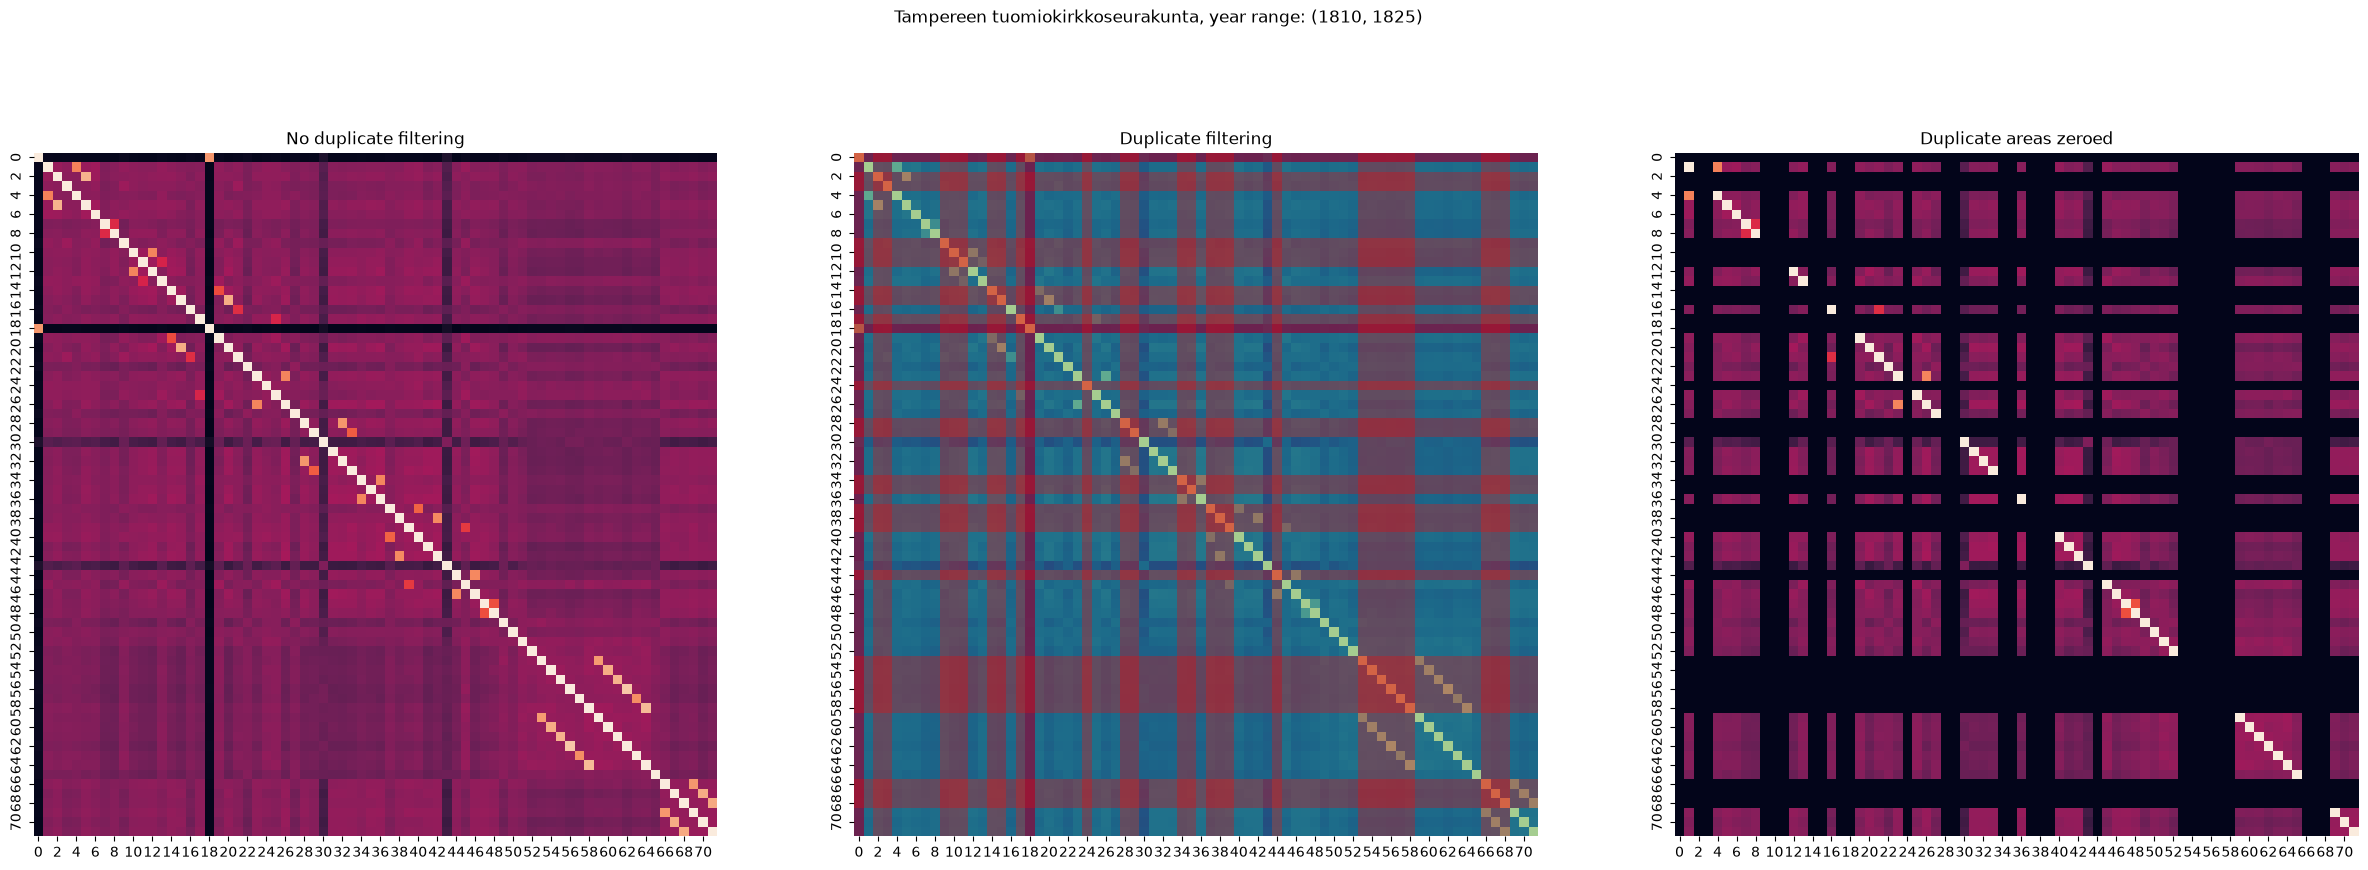

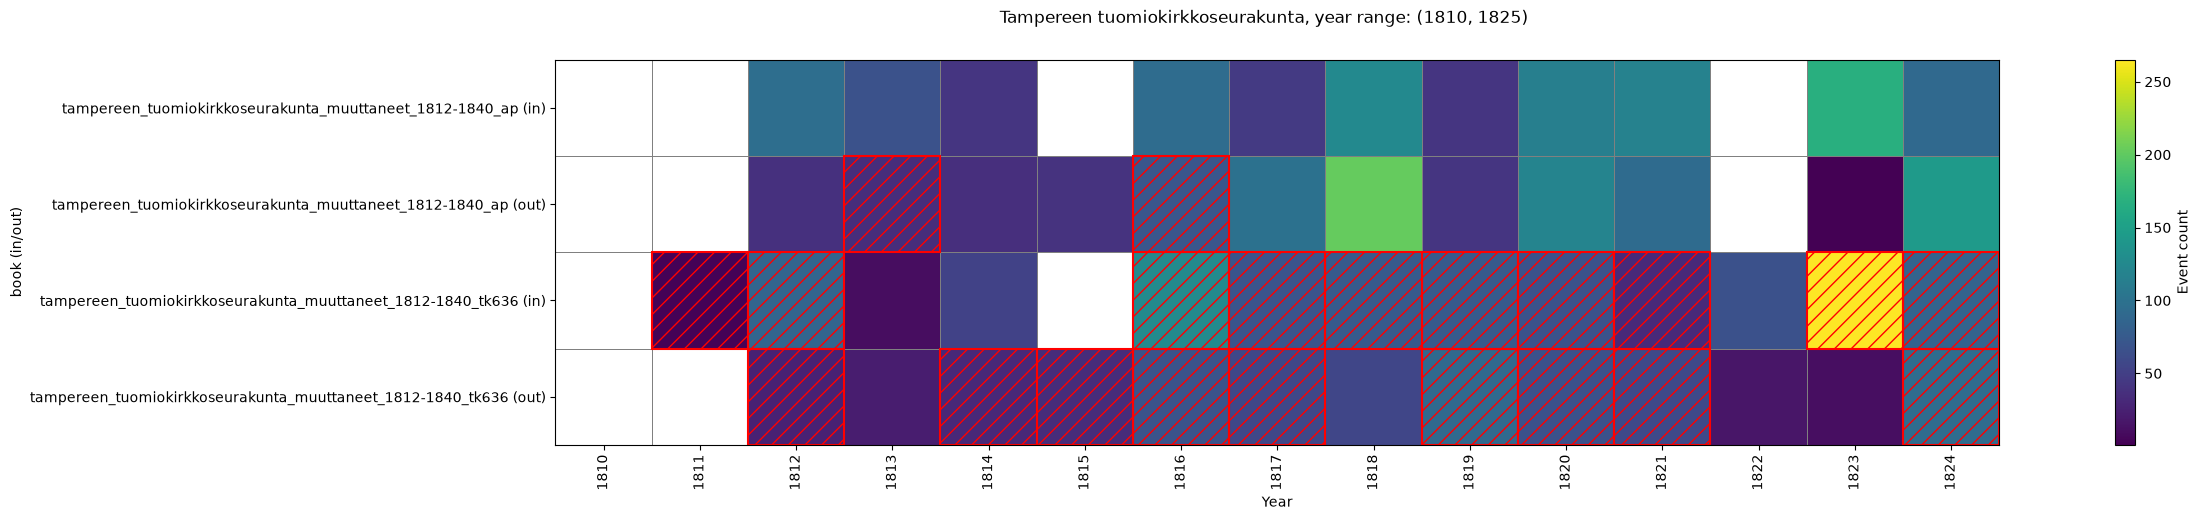

In [2]:
df_tampereen_tuom = pd.read_json(
    f"outputs/json/all_migration_events_parish_splits_duplicate_info/543_migration_events.jsonl",
    lines=True,
)
fig, axs = plot_migration_similarity_heatmaps(
    df_tampereen_tuom,
    "Tampereen tuomiokirkkoseurakunta",
    (1810, 1825),
    scorer=fuzz.ratio,
    vmax=100.0,
)
fig, axs = plot_book_year_event_heatmap(
    df_tampereen_tuom, "Tampereen tuomiokirkkoseurakunta", (1810, 1825)
)
migration_duplicate_filtering_before_after_counts(
    df_tampereen_tuom, (1810, 1825)
)

## Examining whole history of a parish

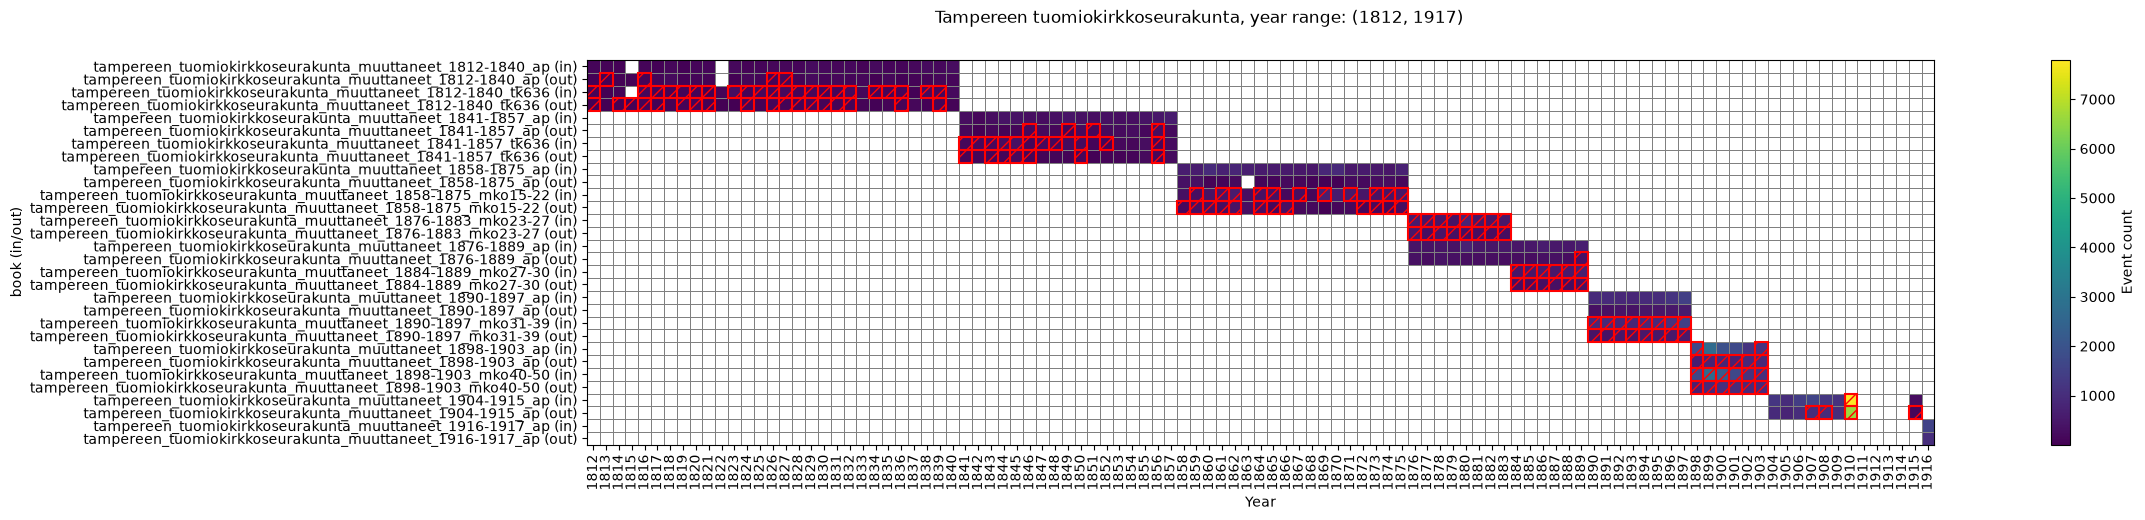

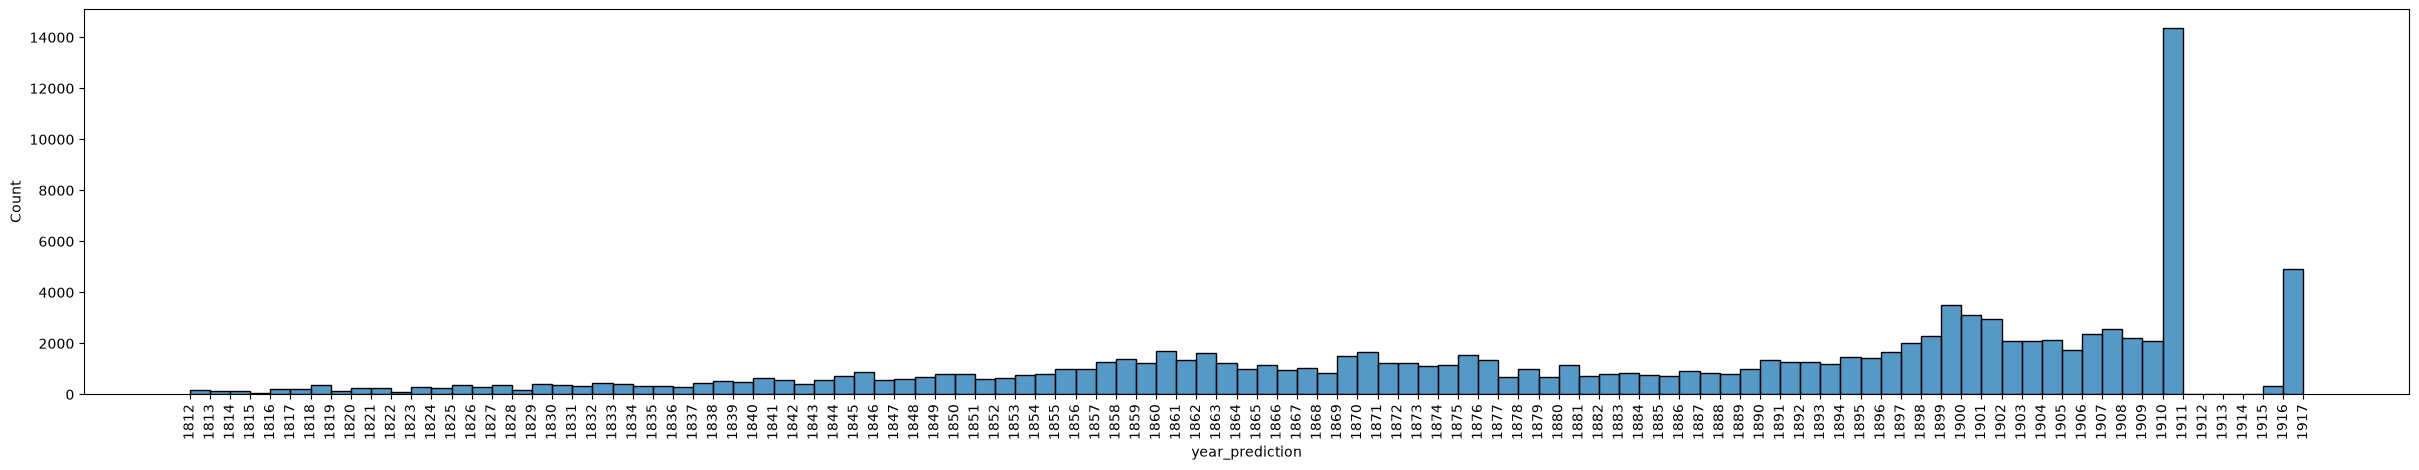

In [3]:
fig, axs = plot_book_year_event_heatmap(df_tampereen_tuom, "Tampereen tuomiokirkkoseurakunta", (1812, 1917))
plot_non_duplicate_migration_histogram(df_tampereen_tuom)

## Overall counts of events

In [ ]:
total_all_events = 0
total_all_events_no_empty_row = 0
total_non_duplicate_events = 0
total_non_duplicate_events_clear_direction = 0
total_non_duplicate_events_no_empty_row = 0
total_non_duplicate_events_clear_direction_no_empty_row = 0

non_duplicate_events_year_counts = defaultdict(int)
non_duplicate_events_year_counts_clear_direction = defaultdict(int)
non_duplicate_events_year_counts_no_empty_row = defaultdict(int)
non_duplicate_events_year_counts_clear_direction_no_empty_row = defaultdict(int)

output_jsonls = list(Path(
    "outputs/json/all_migration_events_parish_splits_duplicate_info"
).glob("*.jsonl"))
for file_path in tqdm(output_jsonls):
    with open(file_path, "r") as fp:
        for line in fp:
            e = json.loads(line)
            total_all_events += 1
            empty_row = True
            if e["has_information"]:
                empty_row = False
                total_all_events_no_empty_row += 1

            if (
                e["duplicate"] == False
                and ((e["in/out"] == "in") or (e["in/out"] == "out"))
                and (e["year_prediction"] in range(
                    *DuplicateConfig.correct_year_prediction_bounds
                ))
            ):
                total_non_duplicate_events += 1
                total_non_duplicate_events_clear_direction += 1
                non_duplicate_events_year_counts_clear_direction[e["year_prediction"]] += 1
                non_duplicate_events_year_counts[e["year_prediction"]] += 1

                if not empty_row:
                    total_non_duplicate_events_no_empty_row += 1
                    non_duplicate_events_year_counts_no_empty_row[e["year_prediction"]] += 1
                    total_non_duplicate_events_clear_direction_no_empty_row += 1
                    non_duplicate_events_year_counts_clear_direction_no_empty_row[e["year_prediction"]] += 1

            elif e["duplicate"] == False:
                total_non_duplicate_events += 1
                non_duplicate_events_year_counts[e["year_prediction"]] += 1
                if not empty_row:
                    total_non_duplicate_events_no_empty_row += 1
                    non_duplicate_events_year_counts_no_empty_row[e["year_prediction"]] += 1

non_duplicates_valid_year = {
    k: v for k, v in non_duplicate_events_year_counts.items() if k in range(
        *DuplicateConfig.correct_year_prediction_bounds
    )
}
non_duplicates_valid_year_no_empty_row = {
    k: v for k, v in non_duplicate_events_year_counts_no_empty_row.items() if k in range(
        *DuplicateConfig.correct_year_prediction_bounds
    )
}
non_duplicate_events_year_counts_valid_year_no_empty_row_clear_direction = {
    k: v for k, v in non_duplicate_events_year_counts_clear_direction_no_empty_row.items() if k in range(
        *DuplicateConfig.correct_year_prediction_bounds
    )

}

print(
    f"Events in total: {total_all_events}",
    f"Rows with no data: {total_all_events - total_all_events_no_empty_row}",
    f"Total non-duplicate events: {total_non_duplicate_events}",
    f"At least {total_all_events - total_non_duplicate_events} duplicate events.",
    f"Total non-duplicate events with clear year prediction: {sum(non_duplicates_valid_year.values())}",
    f"Total non-duplicate events with clear direction and year prediction: {total_non_duplicate_events_clear_direction}",
    f"At least {round(100 * total_non_duplicate_events_clear_direction/total_non_duplicate_events)}% of non-duplicate events have unclear migration direction or year estimation.",
    "--- Excluding rows with no information ---",
    f"Events in total (no empty rows): {total_all_events_no_empty_row}",
    f"Total non-duplicate events (no empty rows): {total_non_duplicate_events_no_empty_row}",
    f"At least {total_all_events_no_empty_row - total_non_duplicate_events_no_empty_row} duplicate events (no empty rows).",
    f"Total non-duplicate events with clear year prediction (no empty rows): {sum(non_duplicates_valid_year_no_empty_row.values())}",
    f"Total non-duplicate events with clear direction and year prediction (no empty rows): {total_non_duplicate_events_clear_direction_no_empty_row}",
    f"At least {round(100 * total_non_duplicate_events_clear_direction_no_empty_row/total_non_duplicate_events_no_empty_row)}% of non-duplicate events have unclear migration direction or year estimation (no empty rows).",
    sep="\n",
)

100%|██████████| 468/468 [00:37<00:00, 12.46it/s]

Events in total: 6403412
Rows with no data: 600585
Total non-duplicate events: 5719162
At least 684250 duplicate events.
Total non-duplicate events with clear year prediction: 4125916
Total non-duplicate events with clear direction and year prediction: 3496696
At least 61% of non-duplicate events have unclear migration direction or year estimation.
--- Excluding rows with no information ---
Events in total (no empty rows): 5802827
Total non-duplicate events (no empty rows): 5176197
At least 626630 duplicate events (no empty rows).
Total non-duplicate events with clear year prediction (no empty rows): 3743825
Total non-duplicate events with clear direction and year prediction (no empty rows): 3179587
At least 61% of non-duplicate events have unclear migration direction or year estimation (no empty rows).


In [21]:
year_start = min(non_duplicates_valid_year.keys())
year_end = max(non_duplicates_valid_year.keys())

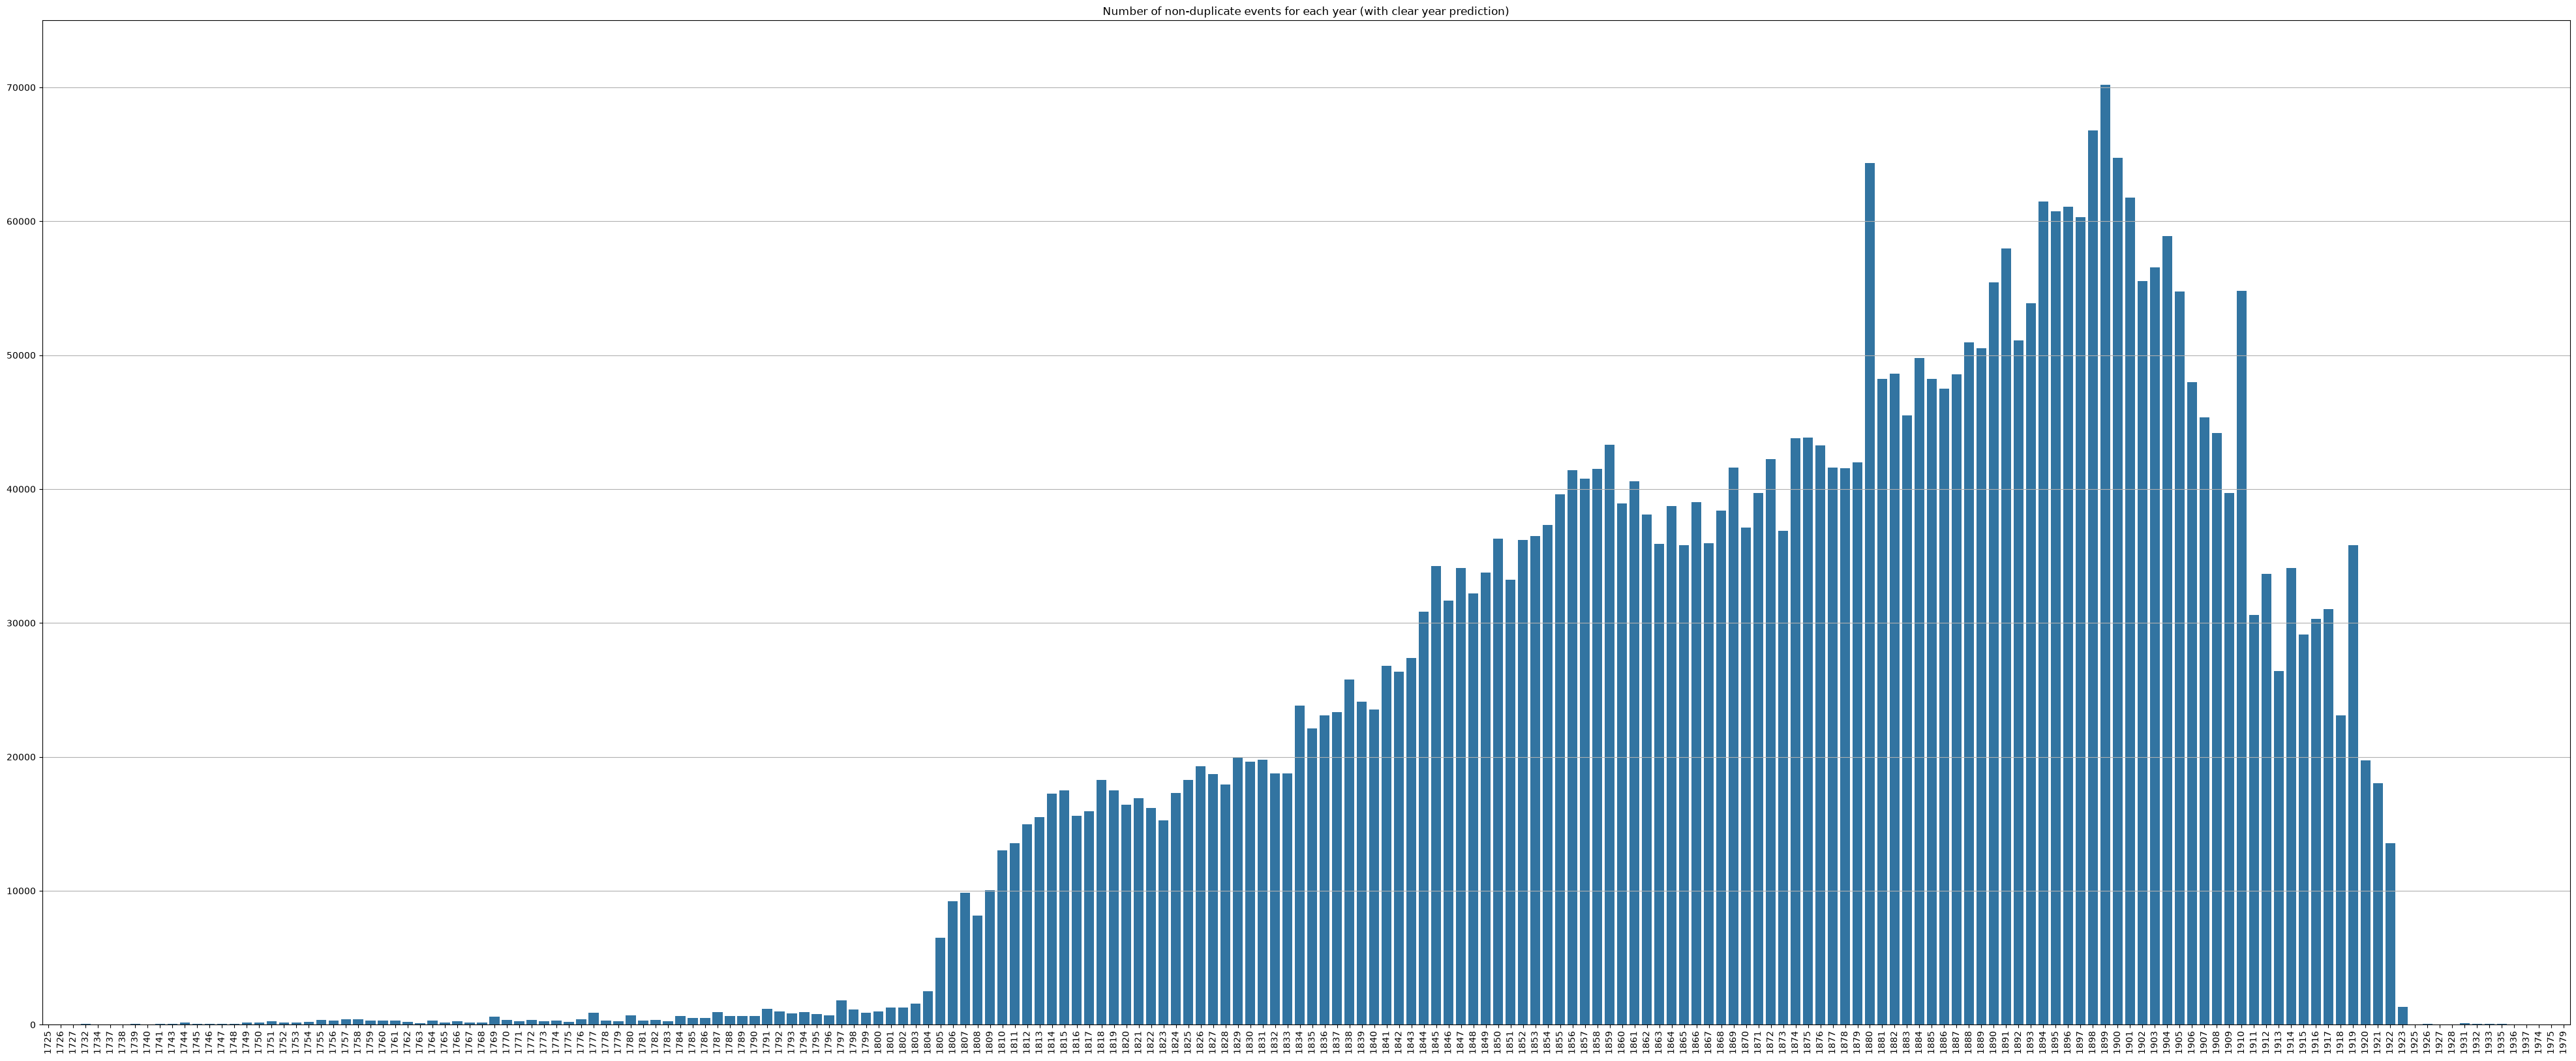

In [22]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in non_duplicates_valid_year.items()]),
    y=tuple([x[1] for x in non_duplicates_valid_year.items()]),
)
axs.set_ylim(0, 75000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(non_duplicates_valid_year.keys()), rotation=90)

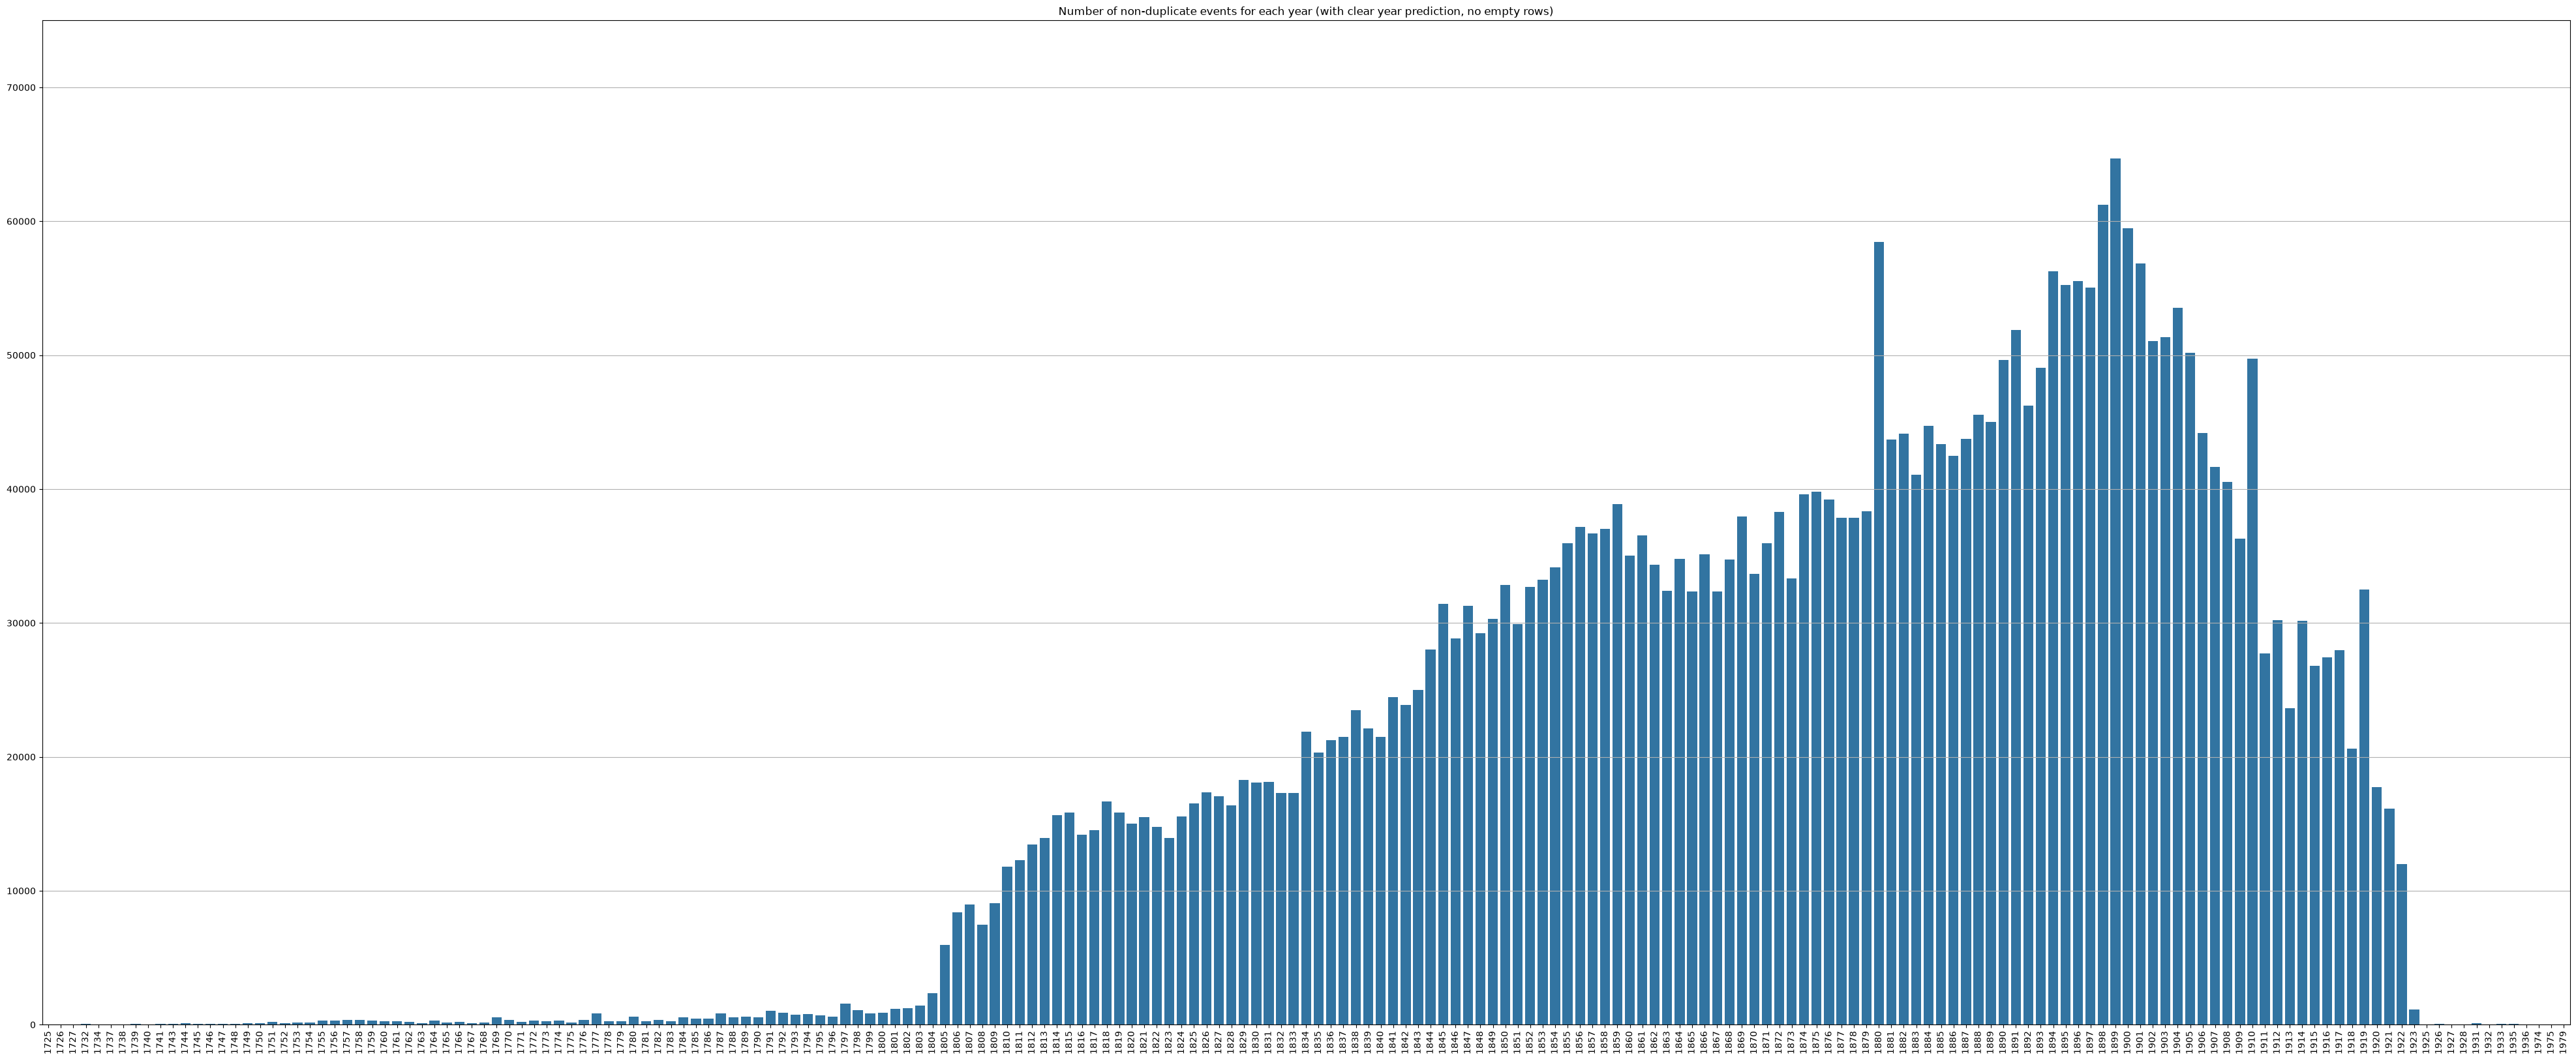

In [23]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in non_duplicates_valid_year_no_empty_row.items()]),
    y=tuple([x[1] for x in non_duplicates_valid_year_no_empty_row.items()])
)
axs.set_ylim(0, 75000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(non_duplicates_valid_year_no_empty_row.keys()), rotation=90)

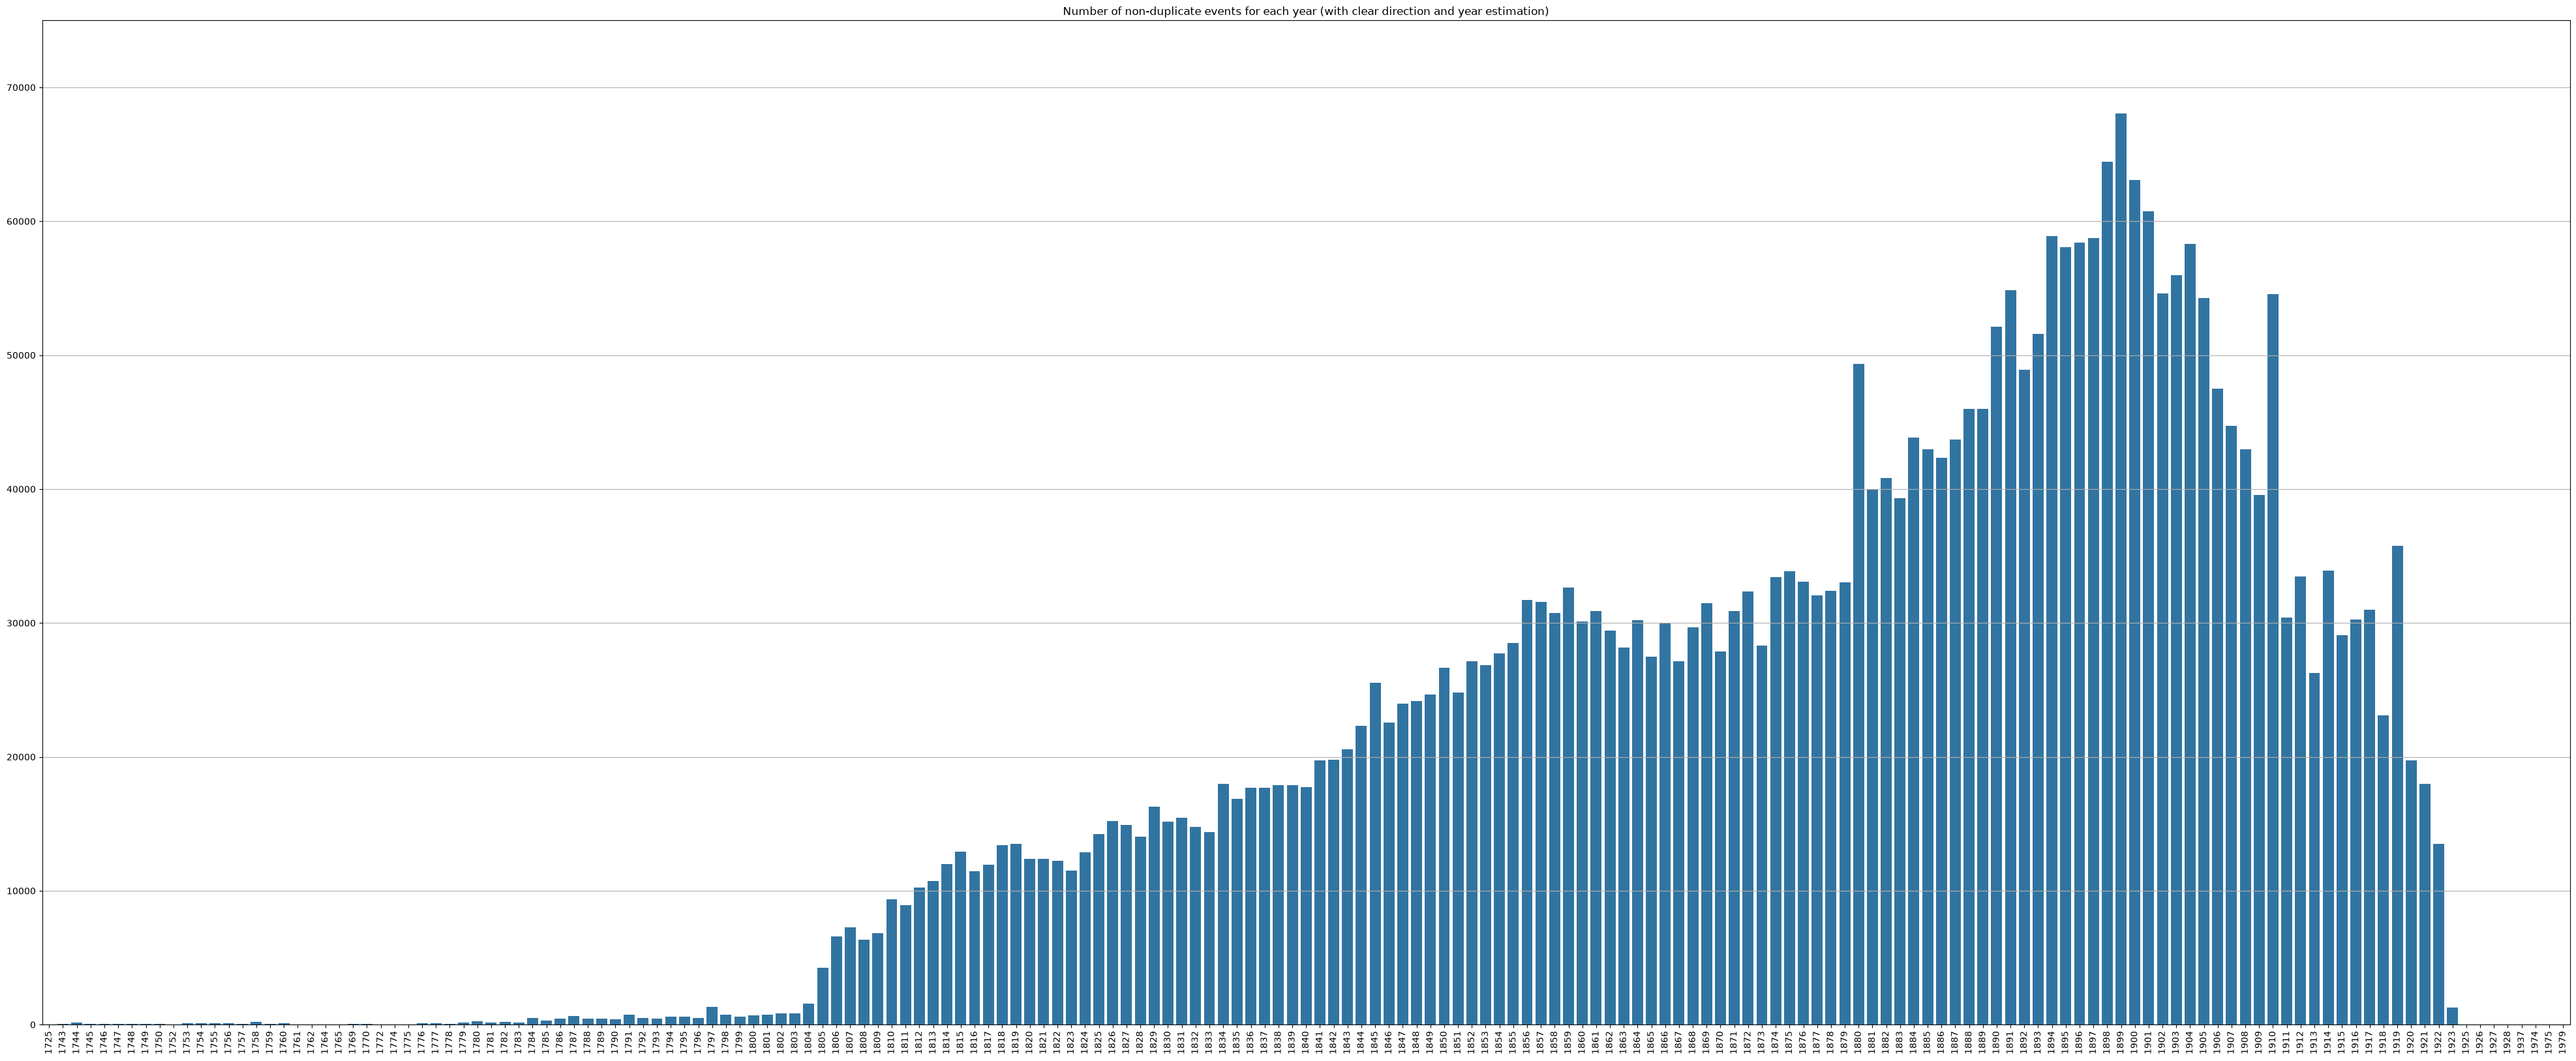

In [24]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in non_duplicate_events_year_counts_clear_direction.items()]),
    y=tuple([x[1] for x in non_duplicate_events_year_counts_clear_direction.items()])
)
axs.set_ylim(0, 75000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear direction and year estimation)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(non_duplicate_events_year_counts_clear_direction.keys()), rotation=90)

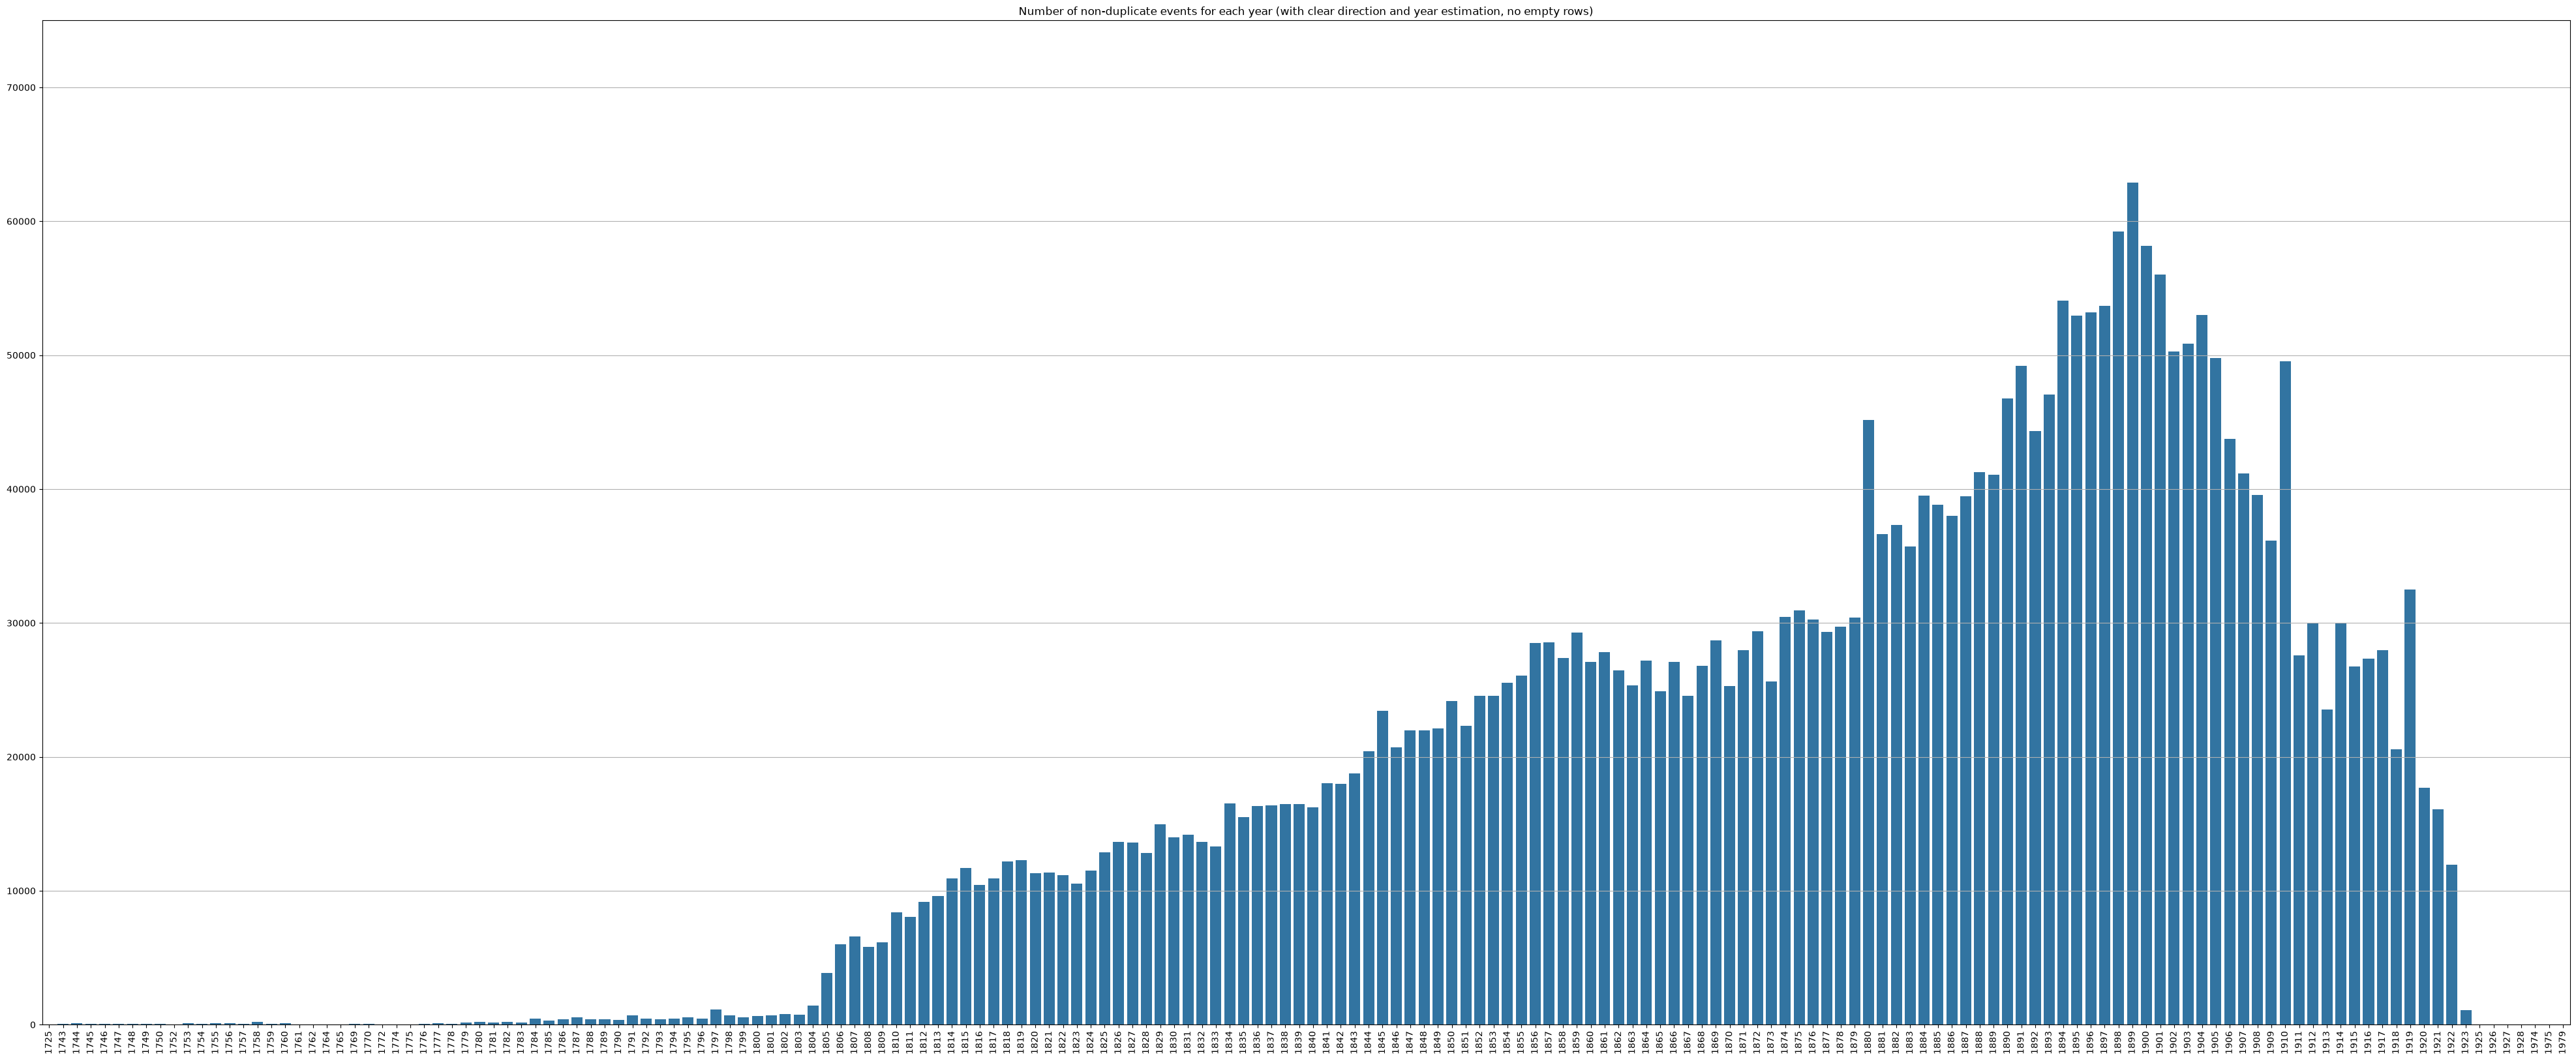

In [ ]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in non_duplicate_events_year_counts_valid_year_no_empty_row_clear_direction.items()]),
    y=tuple([x[1] for x in non_duplicate_events_year_counts_valid_year_no_empty_row_clear_direction.items()])
)
axs.set_ylim(0, 75000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear direction and year estimation, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(non_duplicate_events_year_counts_valid_year_no_empty_row_clear_direction.keys()), rotation=90)